# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Karl Gian
- _Student No._: 2024-09545
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

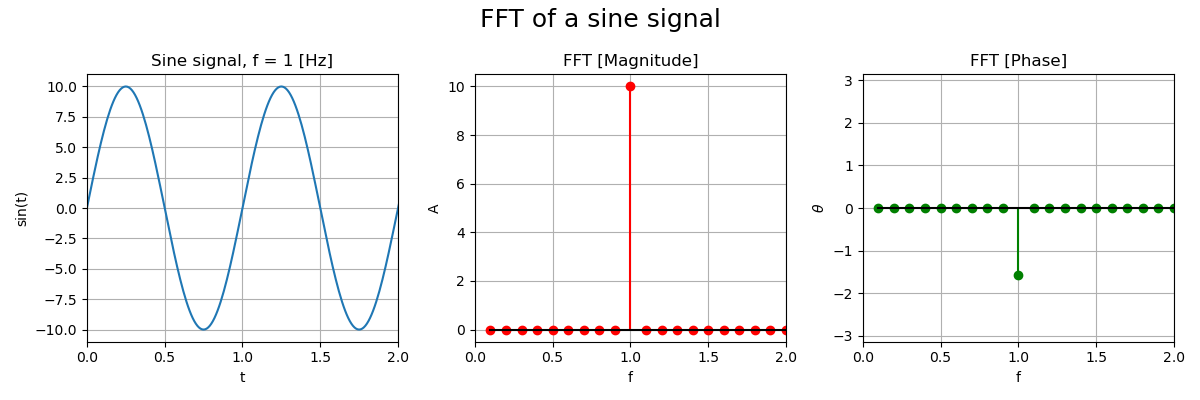

Figure 1a shows the original sine signal, as well as the magnitude and phase FFT plots.

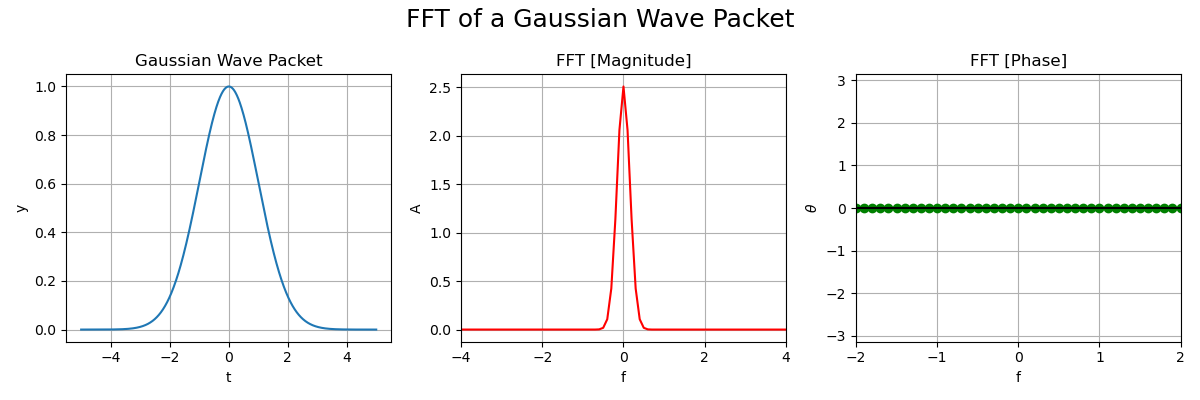

Figure 1b shows the original Gaussian signal, as well as the magnitude and phase FFT plots.

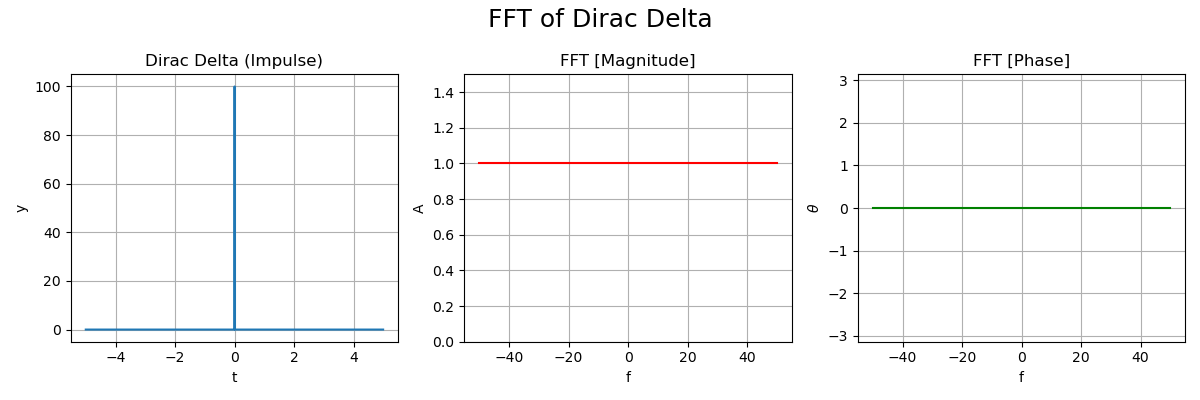

Figure 1c shows the original Dirac-delta signal, as well as the magnitude and phase FFT plots.

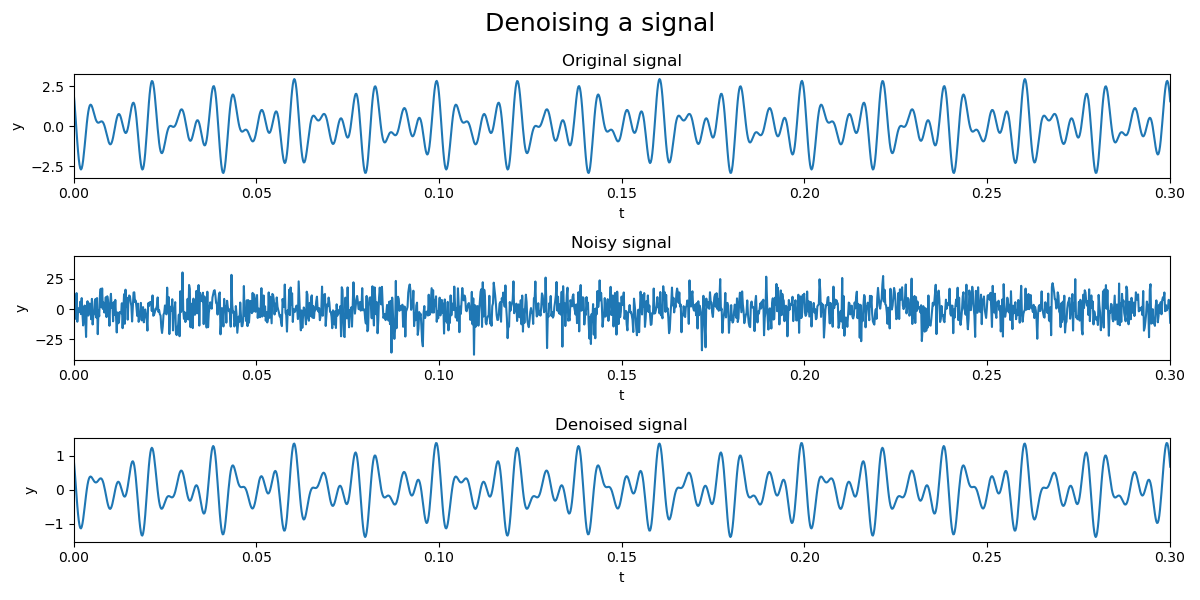

Figure 2a shows the original signal (top), and then mixed with noise (center), and then denoised using a Hanning window and inverse FFT.

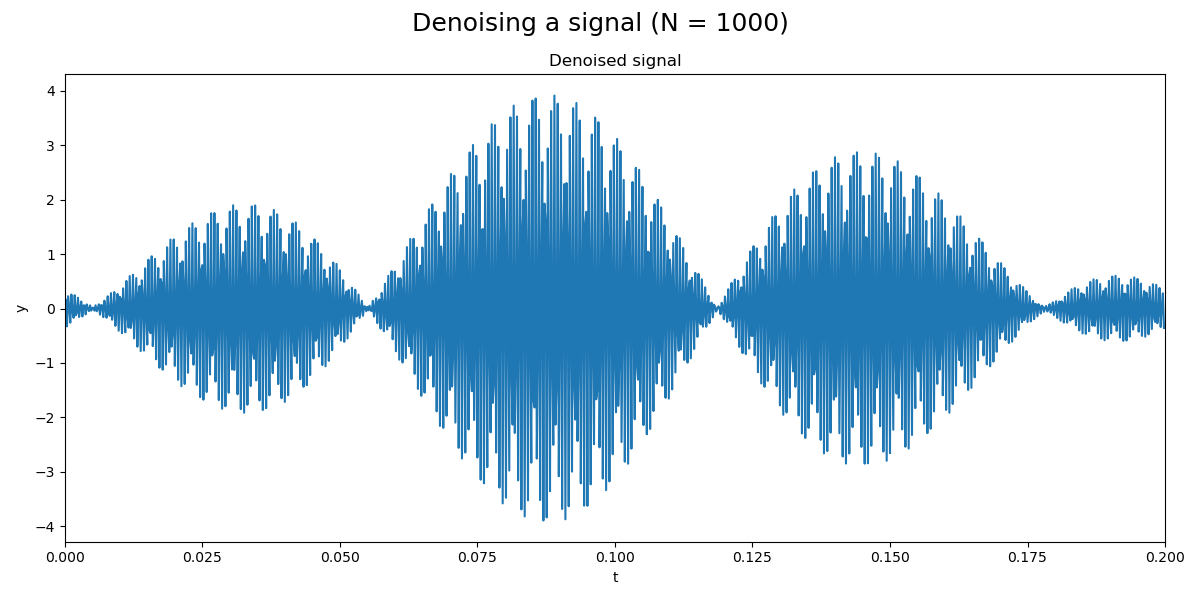

Figure 2b shows the denoising attempt with N = 1000 

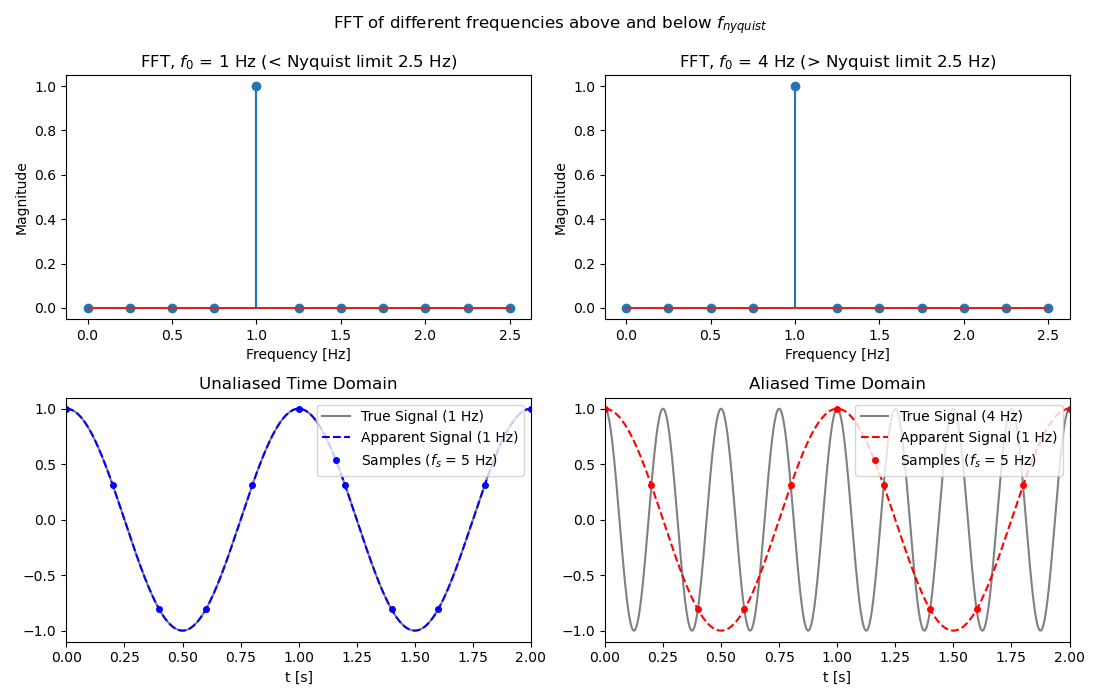

Figure 3 shows how FFT sees an input signal if it were above (left) or below (right) the sampling frequency or Nyquist frequency. Sampling rate for both is 5 Hz.


### Report discussion

#### Problem 1

For a real sine signal, energy splits equally into dual magnitude spikes at $\pm f$ with amplitude $A/2$ and a $-\pi/2$ phase shift relative to the cosine reference (FFT). A Gaussian signal transforms into a reciprocal Gaussian spectrum whose inverse relationship between time domain width and frequency domain width shows the scaling property while maintaining a zero phase due to lack of an imaginary term in the Gaussian function. As the extreme limit of a zero-width Gaussian, the Dirac delta function produces a perfectly flat, constant (in this case, 1, since it is normalized) magnitude spectrum across all frequencies with zero phase.

#### Problem 2

The signal was able to be recovered given that it was taken with a sample size of N = 25000, this was repeated for N = 1000. What was observed was that the signal wasn't properly recovered, and this is due to the fact that when you lower N, the signal peak height also lowers, but the noise will always stay roughly the same height. At some N, there will be a point where the signal frequencies are indistinguishable from the noise. The limit of N at which we can recover the signal well is N such that the signal peak does is no less or equal than the average noise floor.

#### Problem 3

The sampling rate for both the $f_{above} = 4 Hz$ and $f_{below} = 1 Hz$ is 5 Hz, so the Nyquist frequency is 2.5 Hz. Observe that when the signal frequency is less than the Nyquist frequency, we are able to capture the signal accurately such that the FFT spits out something that aligns with reality, otherwise, the FFT becomes unreliable when the signal frequency is less than the Nyquist frequency. This is because for a signal to be captured accurately, you would need to capture it as it goes upwards and downwards when it oscillates, i.e., twice per cycle, if this isn't done then the FFT will see the signal as some lower frequency (alias) given by $|f_0 - f_s|$, where $f_0$ is signal frequency and $f_s$ is sampling rate or Nyquist frequency.



---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

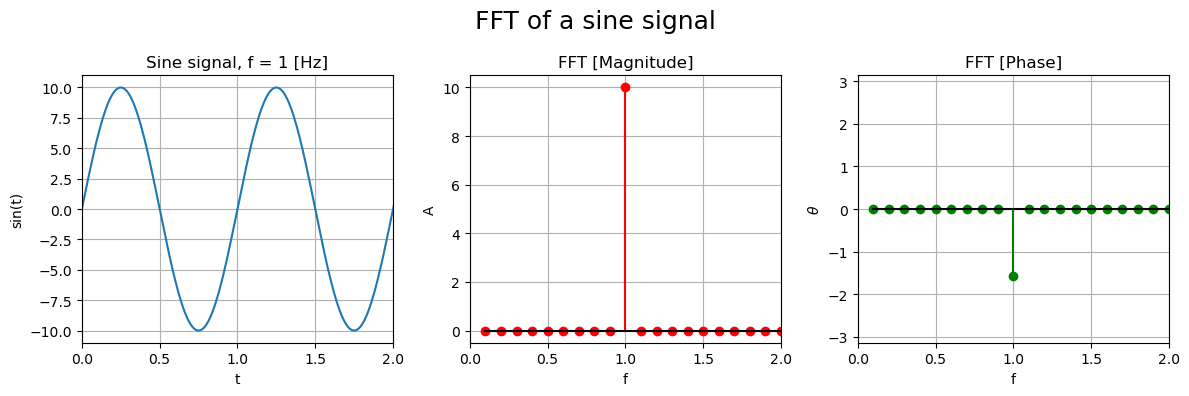

In [2]:
# code here

# sine function
def sine(x, amplitude=10, period=1):
    return amplitude * np.sin(2*np.pi*period*x)

# generate array of numbers
N = 1000
ts = np.linspace(0, 10, N, endpoint = False)
ys = sine(ts,10,1)

# apply the fourier transform
dx = ts[1] - ts[0]
Y = np.fft.fftshift(np.fft.fft(ys))
freqs = np.fft.fftshift(np.fft.fftfreq(len(ts), d=dx)) # must be shifted so that the zero frequency component is cenetered

# get magnitude and phase
mag = np.abs(Y) / (N/2) # normalize by dividing by N/2 instead of multiplying Y with dx. as raw FFT peak is amplitude * number of points / 2
phase = np.angle(Y)

# note that we get the phase at which the magnitude is non-zero 
# so that we actually get the phase of the signal at certain frequency
phase[mag < 1e-4] = 0

fig, ax = plt.subplots(1, 3, figsize = (12, 4))

pos = freqs > 0

ax[0].plot(ts,ys)
ax[0].set_title(f"Sine signal, f = 1 [Hz]")
ax[0].set_ylabel("sin(t)")
ax[0].set_xlabel("t")
ax[0].set_xlim(0,2)

ax[1].stem(freqs[pos], mag[pos], linefmt = 'red', basefmt = 'k-', markerfmt = 'ro')
ax[1].set_title("FFT [Magnitude]")
ax[1].set_ylabel("A")
ax[1].set_xlabel("f")
ax[1].set_xlim(0,2)

ax[2].stem(freqs[pos], phase[pos], linefmt = 'green', basefmt = 'k-', markerfmt = 'go')
ax[2].set_ylim(-np.pi, np.pi)
ax[2].set_title("FFT [Phase]")
ax[2].set_ylabel(r"$\theta$")
ax[2].set_xlabel("f")
ax[2].set_xlim(0, 2)

for i in range(len(ax)): ax[i].grid()

fig.suptitle("FFT of a sine signal", fontsize = '18')
fig.tight_layout()

plt.savefig("problem1.png")
plt.show()

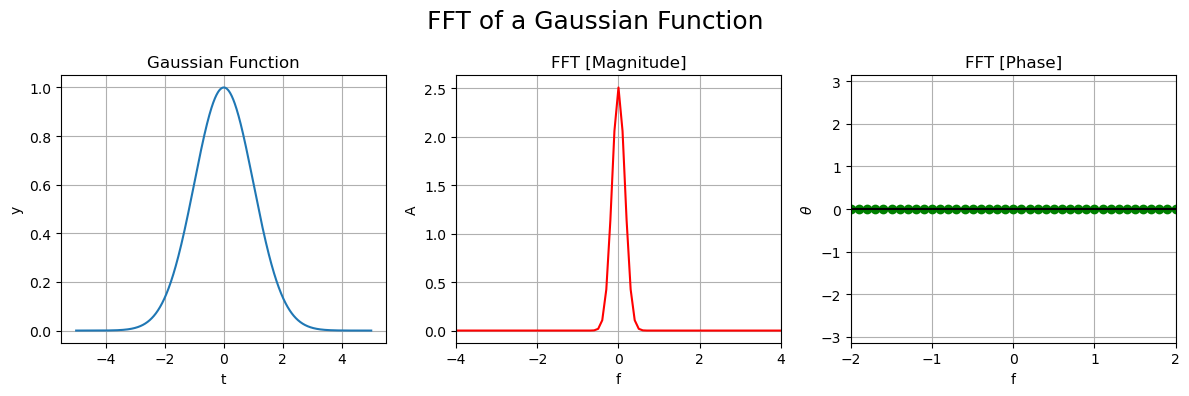

In [3]:
def gaussian(x, x0=0, sigma=1):
    return np.exp(-(x - x0)**2 / (2 * sigma**2))

N = 1000
ts = np.linspace(-5, 5, N, endpoint=False)
ys = gaussian(ts, x0=0, sigma=1)

dx = ts[1] - ts[0]
# shift t=0 to index 0 before calling fft since fft assumes start at t = 0
# then shift it back to original again
Y = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(ys)))
freqs = np.fft.fftshift(np.fft.fftfreq(len(ts), d=dx))

# use * dx for continuous pulse signals, different for transient signals like sine
mag = np.abs(Y) * dx
phase = np.angle(Y)

phase[mag < 1e-3 * np.max(mag)] = 0

# Plotting
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].plot(ts, ys)
ax[0].set_title("Gaussian Function")
ax[0].set_ylabel("y")
ax[0].set_xlabel("t")

ax[1].plot(freqs, mag, color='red')
ax[1].set_title("FFT [Magnitude]")
ax[1].set_ylabel("A")
ax[1].set_xlabel("f")
ax[1].set_xlim(-4, 4)

ax[2].stem(freqs, phase, linefmt='green', basefmt='k-', markerfmt='go')
ax[2].set_ylim(-np.pi, np.pi)
ax[2].set_title("FFT [Phase]")
ax[2].set_ylabel(r"$\theta$")
ax[2].set_xlabel("f")
ax[2].set_xlim(-2, 2)

for a in ax:
    a.grid()

fig.suptitle("FFT of a Gaussian Function", fontsize = '18')
fig.tight_layout()

plt.savefig("problem1b.png")
plt.show()

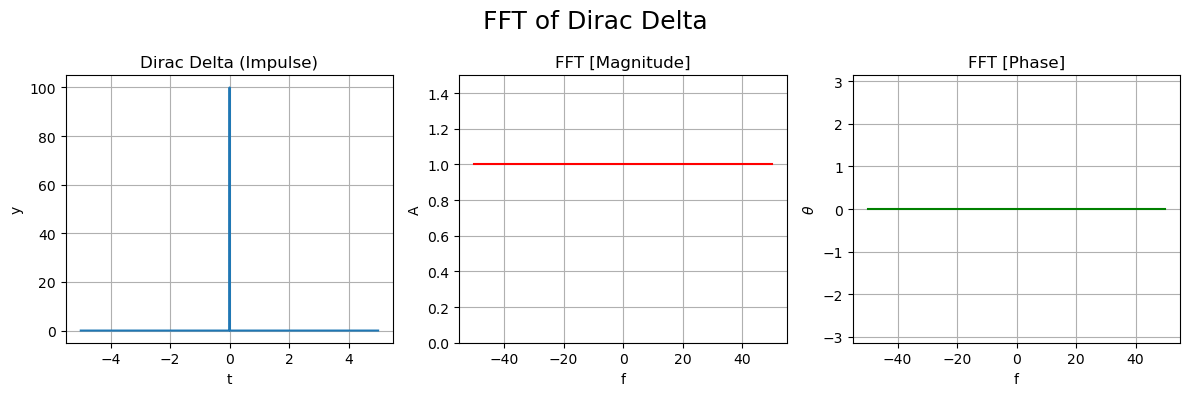

In [4]:
from scipy.signal import unit_impulse  

# same thing with above
N = 1000
ts = np.linspace(-5,5, N, endpoint = False)
dx = ts[1]- ts[0]
ys = unit_impulse(len(ts), 'mid') / dx # divide by dx to discretize. so that if multiplied by dx, th height is one.

# shift t=0 to index 0 before calling fft since fft assumes start at t = 0
# then shift it back to original again
Y = np.fft.fftshift(np.fft.fft(np.fft.ifftshift(ys))) * dx
freqs = np.fft.fftshift(np.fft.fftfreq(len(ts), d=dx))

mag = np.abs(Y)
phase = np.angle(Y)
phase[mag < 1e-3 * np.max(mag)] = 0

fig, ax = plt.subplots(1, 3, figsize = (12, 4))

pos = freqs > 0

ax[0].plot(ts,ys)
ax[0].set_title("Dirac Delta (Impulse)")
ax[0].set_ylabel("y")
ax[0].set_xlabel("t")

ax[1].plot(freqs, mag, color='red')
ax[1].set_title("FFT [Magnitude]")
ax[1].set_ylabel("A")
ax[1].set_xlabel("f")
ax[1].set_ylim(0, 1.5)

ax[2].plot(freqs, phase, color='green')
ax[2].set_ylim(-np.pi, np.pi)
ax[2].set_title("FFT [Phase]")
ax[2].set_ylabel(r"$\theta$")
ax[2].set_xlabel("f")

for i in range(len(ax)): ax[i].grid()

fig.suptitle("FFT of Dirac Delta", fontsize = '18')
fig.tight_layout()

plt.savefig("problem1c.png")
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [5]:
#Make a wave (cosine or sine) - you can do combo of waves
N = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(N)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

Text(0.5, 1.0, 'Original Signal')

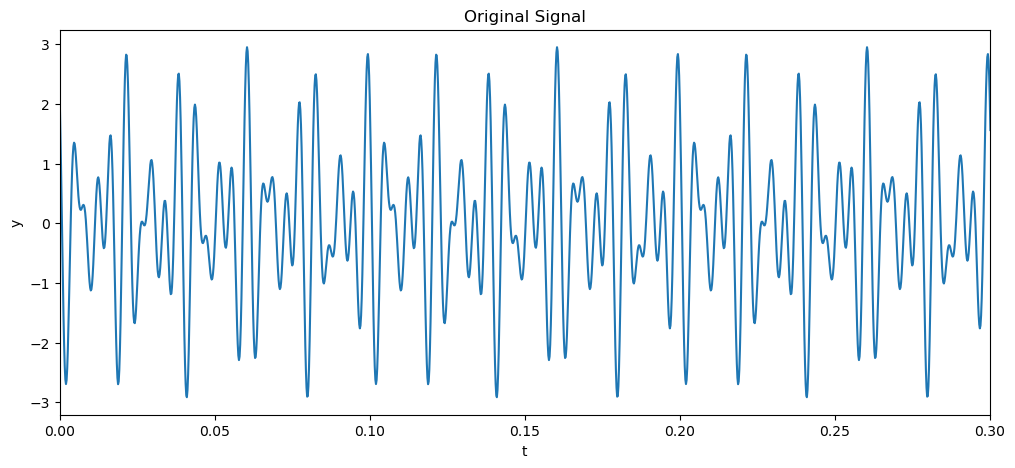

In [6]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)
ax.set_xlabel("t")
ax.set_ylabel("y")
plt.title("Original Signal")


Text(0.5, 0.98, 'Fourier transform of original signal')

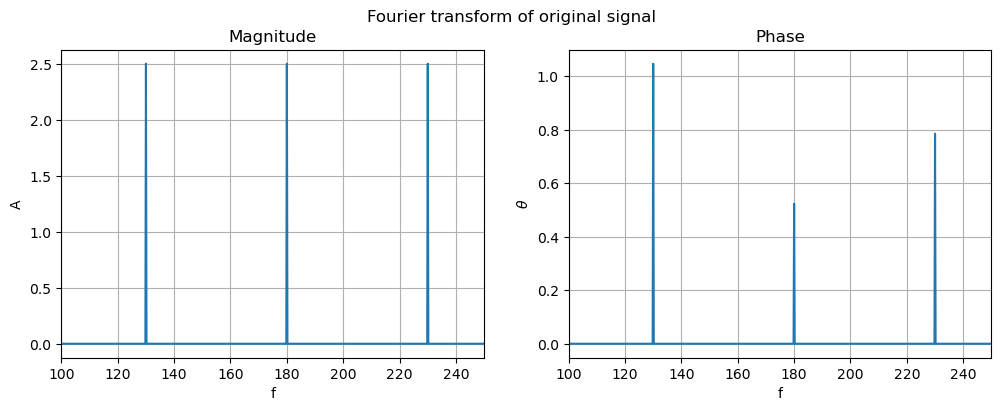

In [7]:
#FILL: Plot the fourier transform of the clean, original signal
ts = t_
ys = signal_original

dx = ts[1]- ts[0]
Y = np.fft.fftshift(np.fft.fft(ys)) * dx
freqs = np.fft.fftshift(np.fft.fftfreq(len(ts), d=dx))

mag = np.abs(Y)
phase = np.angle(Y)
phase[mag < 1] = 0

fig, ax = plt.subplots(1, 2, figsize = (12, 4))

pos = freqs > 0
ax[0].plot(freqs[pos], mag[pos])
ax[0].set_title("Magnitude")
ax[0].set_ylabel("A")
ax[0].set_xlabel("f")
ax[0].set_xlim(100,250)

ax[1].plot(freqs[pos], phase[pos])
ax[1].set_title("Phase")
ax[1].set_ylabel(r"$\theta$")
ax[1].set_xlabel("f")
ax[1].set_xlim(100,250)

for i in range(len(ax)): ax[i].grid()

fig.suptitle("Fourier transform of original signal")

In [8]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

Text(0.5, 0, 't')

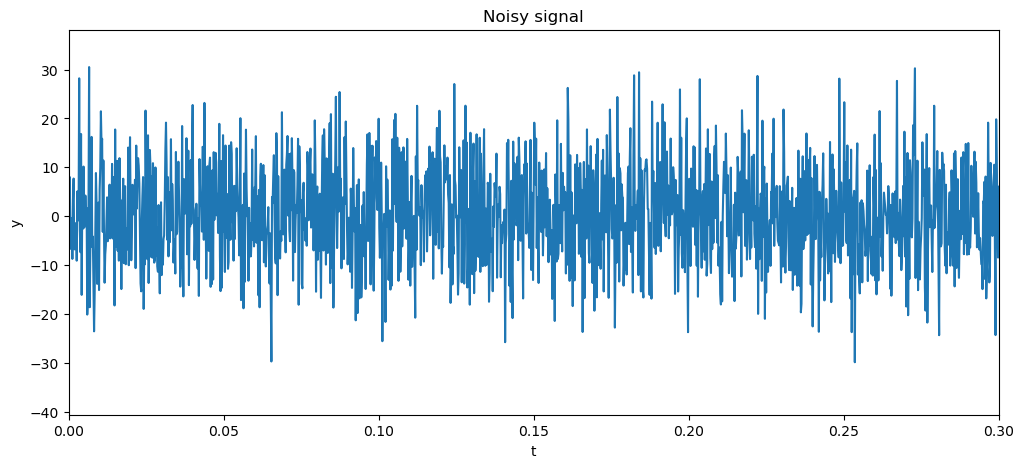

In [9]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)
ax.set_title("Noisy signal")
ax.set_ylabel("y")
ax.set_xlabel("t")

Text(0.5, 1.0, 'Hanning Window')

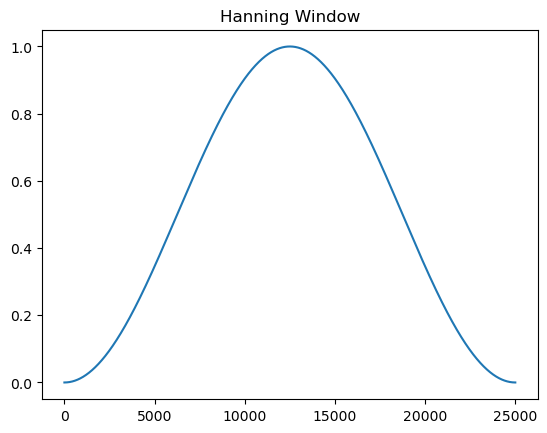

In [10]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)
plt.title("Hanning Window")

In [11]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(N, dt))


Text(0.5, 1.0, 'Fourier Transform of Hanning Window')

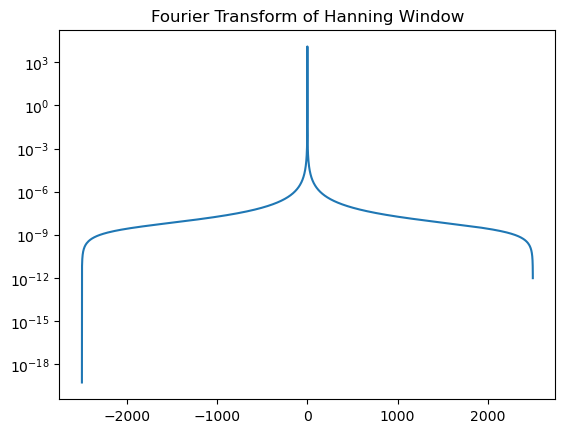

In [12]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')
plt.title('Fourier Transform of Hanning Window')

In [13]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))


Text(0, 0.5, 'A')

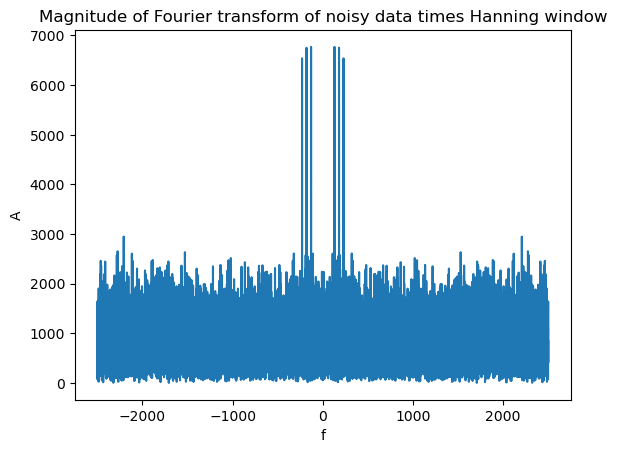

In [14]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window

plt.plot(windowSigFreqs, noisySigPeaks)
plt.title("Magnitude of Fourier transform of noisy data times Hanning window")
plt.xlabel("f")
plt.ylabel("A")

Text(0, 0.5, 'A')

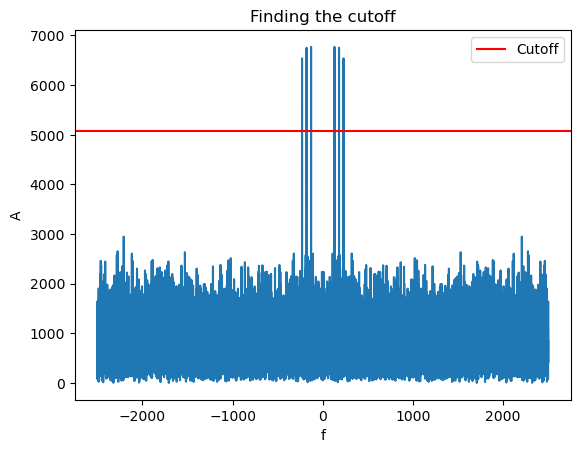

In [15]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
# i.e., we just want to keep the very high spikes. 0.75 seems to do it.
mag = np.abs(noisySigPeaks)
threshold = 0.75*mag.max()

plt.plot(windowSigFreqs, noisySigPeaks)
plt.axhline(threshold, color = 'r', label = "Cutoff")
plt.legend()
plt.title("Finding the cutoff")
plt.xlabel("f")
plt.ylabel("A")

In [16]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain
filtered_noisyFourier = np.where(np.abs(noisyFourier) >= threshold, noisyFourier, 0)
denoised = np.fft.ifft(filtered_noisyFourier).real

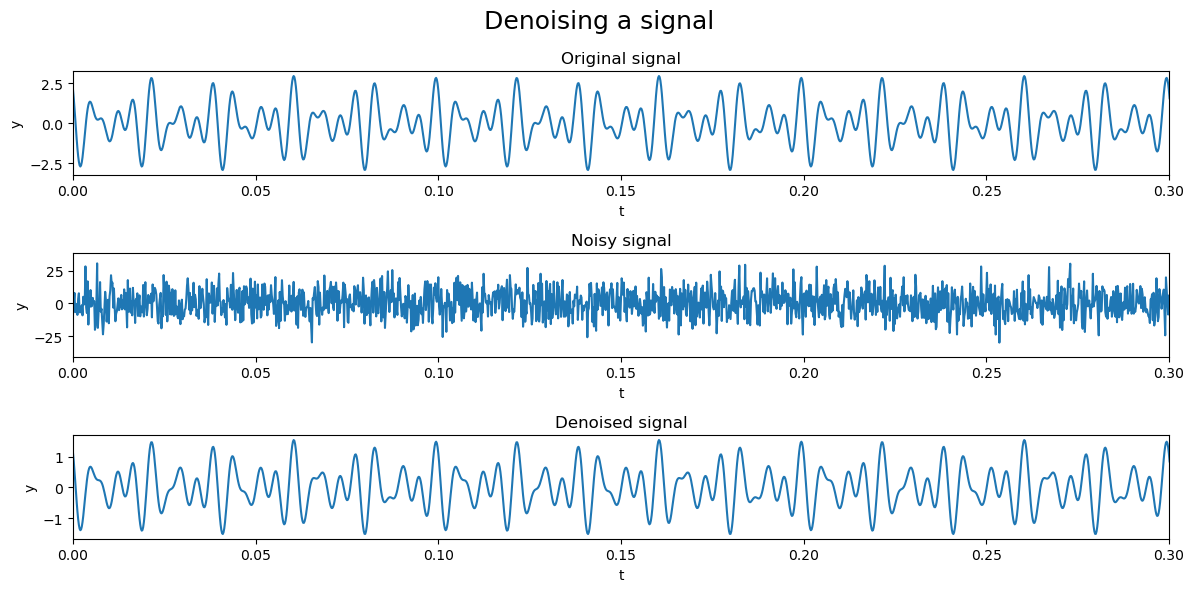

In [17]:
# Plot the recovered signal
fig, ax = plt.subplots(3,1, figsize= (12,6))

ax[0].plot(t_, signal_original)
ax[0].set_xlim(0,0.3)
ax[0].set_title("Original signal")
ax[0].set_xlabel("t")
ax[0].set_ylabel("y")

ax[1].plot(t_, noisy_data)
ax[1].set_xlim(0,0.3)
ax[1].set_title("Noisy signal")
ax[1].set_ylabel("y")
ax[1].set_xlabel("t")

ax[2].plot(t_, denoised)
ax[2].set_xlim(0,0.3)
ax[2].set_title("Denoised signal")
ax[2].set_ylabel('y')
ax[2].set_xlabel('t')

fig.suptitle("Denoising a signal", fontsize = 18)
fig.tight_layout()

plt.savefig("problem2.png")
plt.show()

In [ ]:
'''
# plotting N = 1000 denoise
fig, ax = plt.subplots(figsize= (12,6))

ax.plot(t_, denoised)
ax.set_xlim(0,0.3)
ax.set_title("Denoised signal")
ax.set_ylabel('y')
ax.set_xlabel('t')

fig.suptitle("Denoising a signal (N = 1000)", fontsize = 18)
fig.tight_layout()

plt.savefig("problem2b.png")
plt.show()
'''

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

In [18]:
'''
nyquist freq = fs/2
'''
# params
fs = 5  # sampling rate
f_nyquist = fs / 2  # this is the nyquist frequency
T = 4  # Period [s]

# Frequencies relative to 2.5 Hz Nyquist limit
f0_below = 1  # 1 < 2.5
f0_above = 4  # 4 > 2.5
# 2. Discrete Sampling
t = np.arange(0, T, 1 / fs)
x_below = np.cos(2 * np.pi * f0_below * t)
x_above = np.cos(2 * np.pi * f0_above * t)

# 3. Fourier Transforms
X_below = np.abs(np.fft.rfft(x_below)) / len(x_below) * 2
X_above = np.abs(np.fft.rfft(x_above)) / len(x_above) * 2
f_axis = np.fft.rfftfreq(len(t), 1 / fs)  # frequency axis 0 to 2.5 Hz

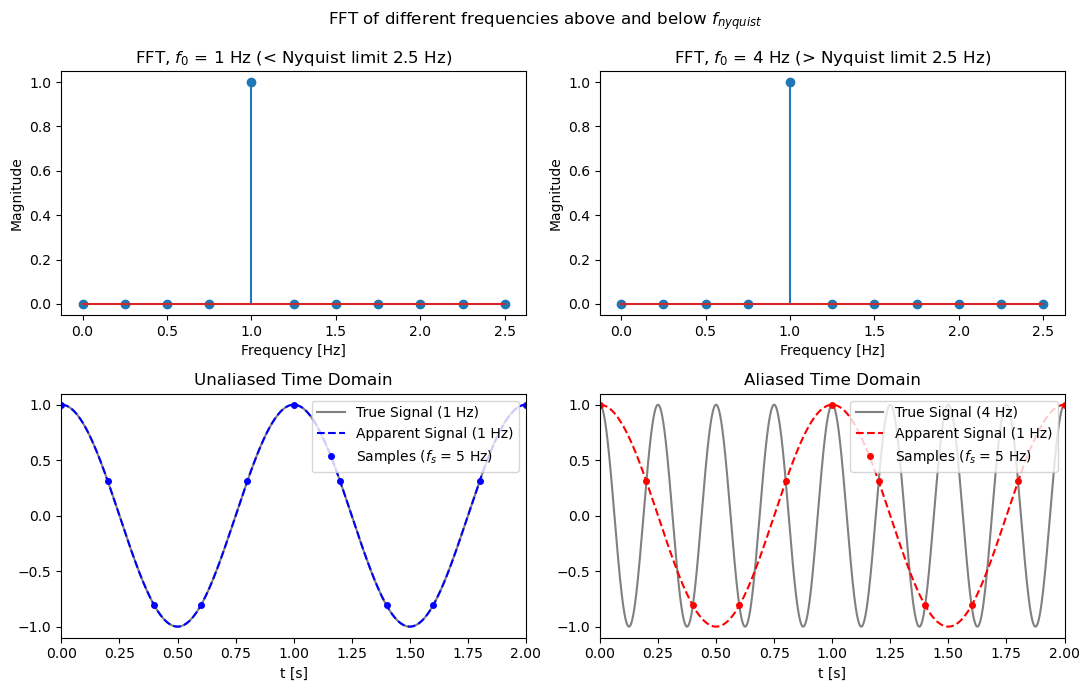

In [19]:
t_true = np.linspace(0, T, 5000)
true_below = np.cos(2 * np.pi * f0_below * t_true)
true_above = np.cos(2 * np.pi * f0_above * t_true)

'''
for a signal below the nyquist frequency, the signal is mathematically identical to a lower frequency
so the fft will see it as the absolute difference between the signal frequency and sampling rate
'''
f_alias = np.abs(f0_above - fs)  # |4 - 5| = 1 Hz
alias_wave = np.cos(2 * np.pi * f_alias * t_true)

fig, ax = plt.subplots(2, 2, figsize=(11, 7))

# unaliased
ax[0, 0].stem(f_axis, X_below)
ax[0, 0].set_title(f"FFT, $f_0$ = {f0_below} Hz (< Nyquist limit {f_nyquist} Hz)")
ax[0, 0].set_xlabel("Frequency [Hz]")
ax[0, 0].set_ylabel("Magnitude")

# aliased
ax[0, 1].stem(f_axis, X_above)
ax[0, 1].set_title(f"FFT, $f_0$ = {f0_above} Hz (> Nyquist limit {f_nyquist} Hz)")
ax[0, 1].set_xlabel("Frequency [Hz]")
ax[0, 1].set_ylabel("Magnitude")

# unaliased
ax[1, 0].plot(
    t_true, true_below, color="gray", label=f"True Signal ({f0_below} Hz)"
)
ax[1, 0].plot(
    t_true, true_below, "b--", label=f"Apparent Signal ({f0_below} Hz)"
)
ax[1, 0].plot(t, x_below, "bo", ms=4, label=f"Samples ($f_s$ = {fs} Hz)")
ax[1, 0].set_title("Unaliased Time Domain")
ax[1, 0].set_xlim(0, 2)
ax[1, 0].set_xlabel("t [s]")
ax[1, 0].legend(loc="upper right")

# aliased
ax[1, 1].plot(
    t_true, true_above, color="gray", label=f"True Signal ({f0_above} Hz)"
)
ax[1, 1].plot(
    t_true, alias_wave, "r--", label=f"Apparent Signal ({f_alias} Hz)"
)
ax[1, 1].plot(t, x_above, "ro", ms=4, label=f"Samples ($f_s$ = {fs} Hz)")
ax[1, 1].set_title("Aliased Time Domain")
ax[1, 1].set_xlim(0, 2)
ax[1, 1].set_xlabel("t [s]")
ax[1, 1].legend(loc="upper right")

fig.suptitle(r"FFT of different frequencies above and below $f_{nyquist}$")

plt.tight_layout()
plt.savefig("problem3.png")
plt.show()

#### Problem code summary

We explored the usage of the Fast Fourier Transform (FFT) and its inverse via the ```numpy``` library, making use of the built-in FFT, inverse FFT, shifting, and all the other functions. The scipy library was also used to properly provide a "Dirac-Delta" function since defining one from scratch didn't really work well with the FFT functions of ```numpy```. In fact, a lot of code here is mainly using libraries since the point is to understand how to use FFT in various problems.

---
## Section 3: Notes

In [20]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

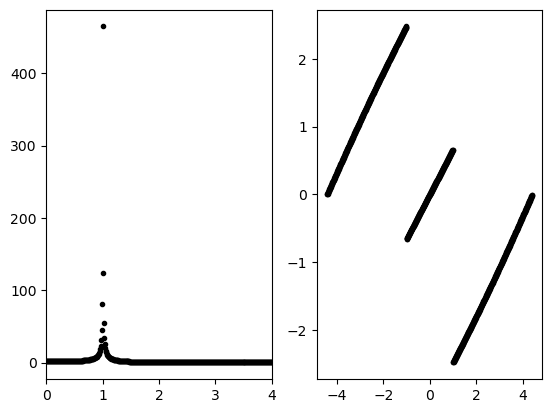

In [21]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [22]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

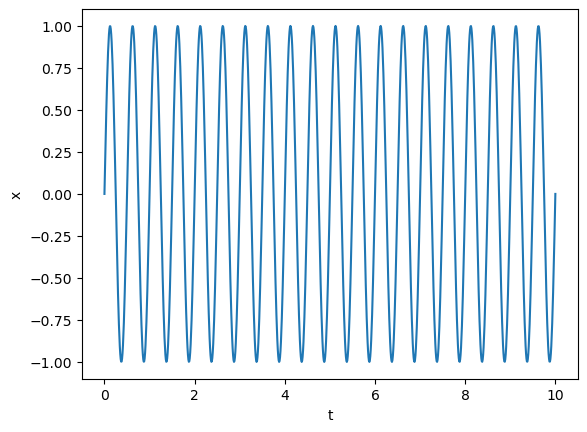

In [23]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [24]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

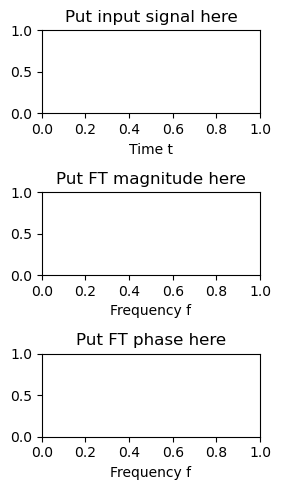

In [25]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

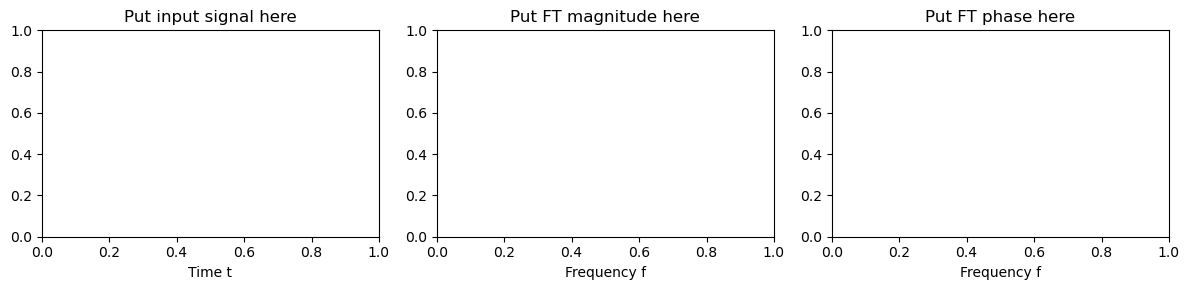

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

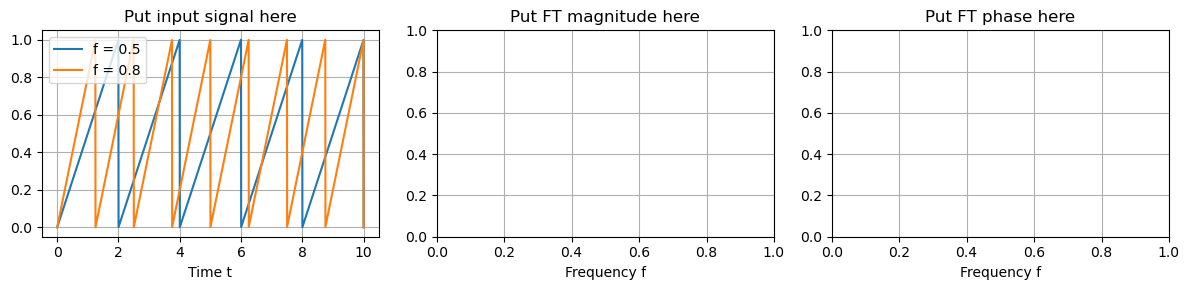

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [28]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



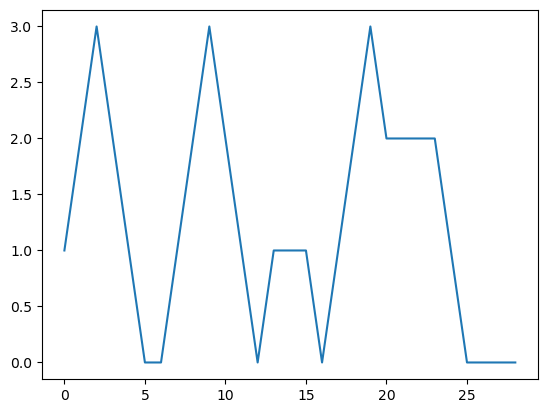

In [29]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [30]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [31]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

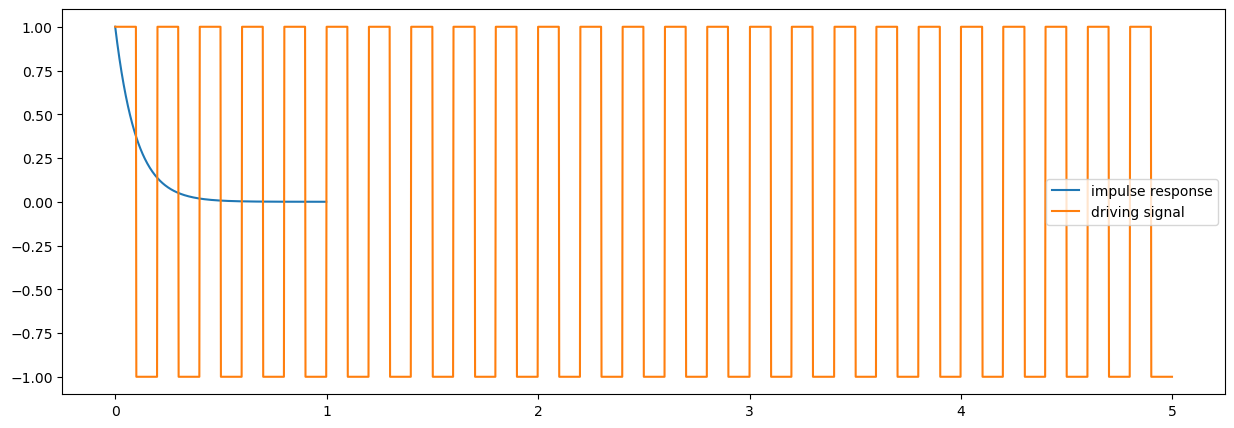

In [32]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [33]:
response = np.convolve(input_signal, h_t, mode = "same")

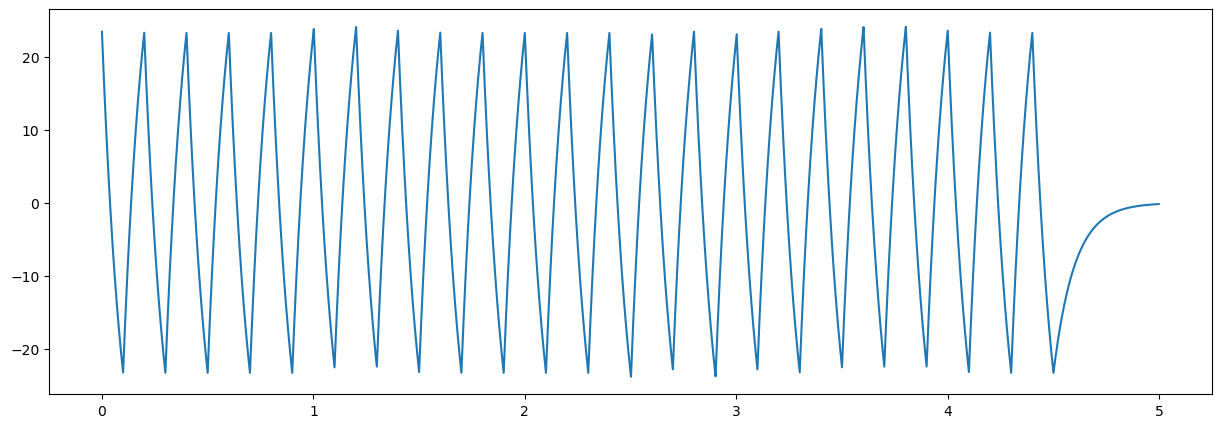

In [34]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [35]:
fourier_length = len(h_t) + len(input_signal) - 1

In [36]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [37]:
fourier_response = fourier_h*fourier_input 

In [38]:
response = np.real(np.fft.ifft(fourier_response))

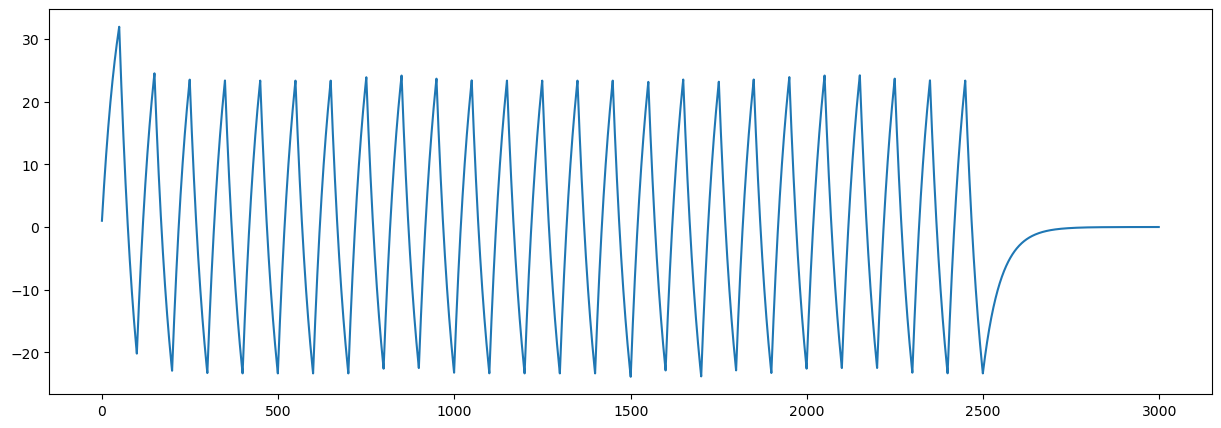

In [39]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)